# EMG-4 | Efficient and Confidence-Aware Gesture Recognition

**Research questions:** (1) Does a validation-tuned hybrid improve gesture recognition relative to competitive classifiers? (2) Can feature reduction and selective prediction improve operating efficiency or reduce incorrect accepted commands?

**Evaluation protocol:** Grouped pseudo-trial partition, validation-only model selection, fixed test evaluation. Original trial boundaries are not provided; the data comes from one wearer, so estimates are exploratory. This dataset has been examined in earlier experiments, and the test set is not a new independent external confirmation.

All performance claims are computed from the uploaded real CSVs. No baseline outputs are altered.

## 1. Setup and reproducibility

In [1]:
from pathlib import Path
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, log_loss, confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings('ignore', category=FutureWarning)
SEED = 42
LABELS = ['Rock','Scissors','Paper','OK']
# Works locally (data/), on Kaggle, and in the original execution environment.
REPO = Path.cwd()
if not (REPO / 'data' / '0.csv').exists() and (REPO.parent / 'data' / '0.csv').exists():
    REPO = REPO.parent  # Notebook opened with notebooks/ as working directory
DATA_CANDIDATES = [REPO / 'data', Path('/kaggle/input/emg-4'), Path('/mnt/data')]
ROOT = next((p for p in DATA_CANDIDATES if all((p / f'{i}.csv').exists() for i in range(4))), None)
if ROOT is None:
    raise FileNotFoundError('EMG-4 CSVs not found. Place 0.csv, 1.csv, 2.csv, 3.csv in data/; see README.md.')
OUT = REPO / 'results'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize':(7.5,4),'figure.dpi':110})
def show_plot(name):
    plt.tight_layout(); plt.savefig(OUT/f'{name}.png',dpi=160,bbox_inches='tight');plt.show();plt.close()
def report(y_true,prob):
    guess=prob.argmax(axis=1)
    return {'accuracy':accuracy_score(y_true,guess),'macro_f1':f1_score(y_true,guess,average='macro'),'balanced_acc':balanced_accuracy_score(y_true,guess),'log_loss':log_loss(y_true,prob,labels=np.arange(4))}
def predict_proba(model,x):
    return model.predict_proba(x)
print('Source:',ROOT,' | Results:',OUT)

Source: /mnt/data  | Results: /mnt/data/EMG4_v4_results


## 2. Load and audit the EMG recordings

Observations: 11678  | Channels: 8  | Raw columns: 64


,gesture,rows,invalid_rows_removed
0,Rock,2910,0
1,Scissors,2903,0
2,Paper,2943,0
3,OK,2922,0


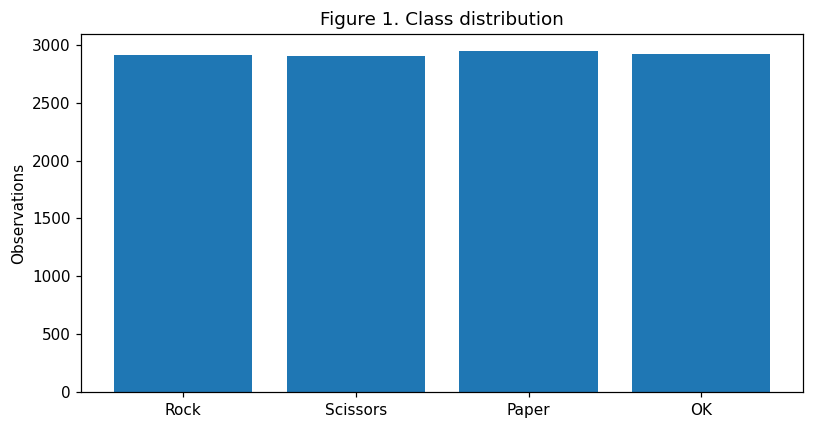

In [2]:
raw,labels,group_ids,summary=[],[],[],[]
for gesture in range(4):
    df=pd.read_csv(ROOT/f'{gesture}.csv',header=None)
    values=df.iloc[:,:64].apply(pd.to_numeric,errors='coerce').to_numpy(np.float32)
    assert values.shape[1]==64
    good=np.isfinite(values).all(axis=1)
    values=values[good]
    count=len(values)
    raw.append(values);labels.append(np.full(count,gesture))
    # Six contiguous blocks per class approximate the six recorded repetitions.
    group_ids.append(gesture*6+np.minimum(np.arange(count)*6//count,5))
    summary.append({'gesture':LABELS[gesture],'rows':count,'invalid_rows_removed':int((~good).sum())})
X=np.concatenate(raw);y=np.concatenate(labels);groups=np.concatenate(group_ids)
df_audit=pd.DataFrame(summary)
print('Observations:',len(y),' | Channels:',8,' | Raw columns:',X.shape[1])
display(df_audit)
plt.bar(df_audit.gesture,df_audit.rows);plt.title('Figure 1. Class distribution');plt.ylabel('Observations');show_plot('01_class_balance')

## 3. Split by approximate recording blocks

In [3]:
block=groups%6
train=np.flatnonzero(block<=3)
valid=np.flatnonzero(block==4)
test=np.flatnonzero(block==5)
assert len(set(groups[train])&set(groups[test]))==0
table_split=pd.DataFrame([{'partition':'Training','samples':len(train),'purpose':'Fit models and meta-learning'},{'partition':'Validation','samples':len(valid),'purpose':'Tune and select'},{'partition':'Test','samples':len(test),'purpose':'Final descriptive evaluation'}])
display(table_split)
print('Caution: inferred blocks are not verified recording boundaries.')

,partition,samples,purpose
0,Training,7786,Fit models and meta-learning
1,Validation,1947,Tune and select
2,Test,1945,Final descriptive evaluation


Caution: inferred blocks are not verified recording boundaries.


## 4. Engineer compact signal features

Feature matrix: (11678, 104) (64 raw + 40 engineered)


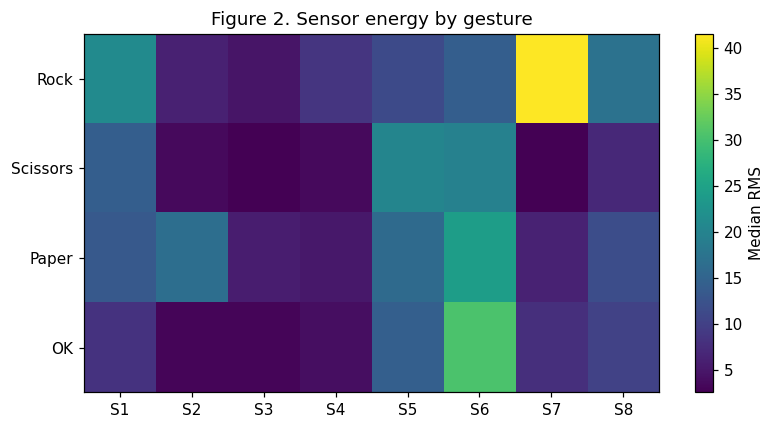

In [4]:
def make_features(raw):
    v=np.asarray(raw,dtype=np.float32).reshape(-1,8,8)
    mean=v.mean(axis=1);std=v.std(axis=1)
    rms=np.sqrt(np.mean(v*v,axis=1))
    wave=np.abs(np.diff(v,axis=1)).mean(axis=1)
    zc=(np.signbit(v[:,1:,:])!=np.signbit(v[:,:-1,:])).mean(axis=1)
    return np.hstack([v.reshape(-1,64),mean,std,rms,wave,zc]).astype(np.float32)
features=make_features(X)
names=[f'S{s+1}_time{t+1}' for t in range(8) for s in range(8)]
names += [f'{k}_S{s+1}' for k in ['mean','std','rms','wave','zero_cross'] for s in range(8)]
print('Feature matrix:',features.shape,'(64 raw + 40 engineered)')
values=np.sqrt((X.reshape(-1,8,8)**2).mean(axis=1))
heat=np.vstack([np.median(values[y==k],axis=0) for k in range(4)])
plt.imshow(heat,aspect='auto',cmap='viridis');plt.xticks(range(8),[f'S{i+1}' for i in range(8)]);plt.yticks(range(4),LABELS);plt.colorbar(label='Median RMS');plt.title('Figure 2. Sensor energy by gesture');show_plot('02_signal_heatmap')

## 5. Training-only feature selection

,feature,importance
0,rms_S7,0.1011
1,std_S7,0.0945
2,wave_S7,0.0739
3,rms_S2,0.0559
4,std_S2,0.0481
5,wave_S2,0.0443
6,rms_S6,0.0329
7,wave_S6,0.0265
8,std_S6,0.0265
9,wave_S4,0.0196


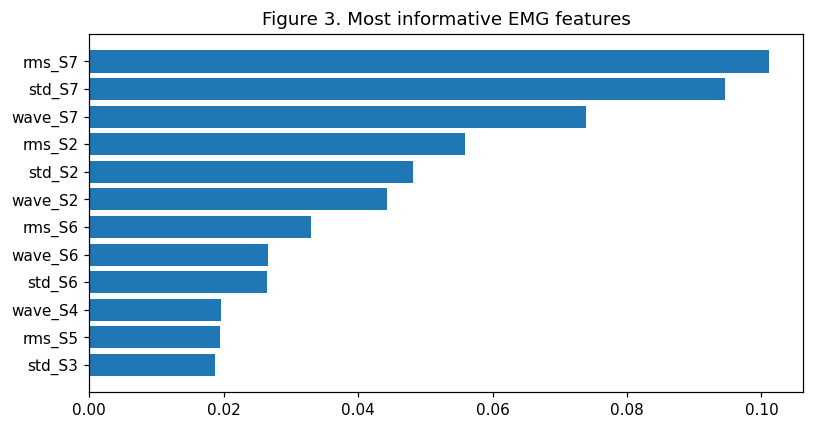

,features,validation_macro_f1
0,16,0.9579
1,32,0.9549
2,64,0.9554
3,104,0.9539


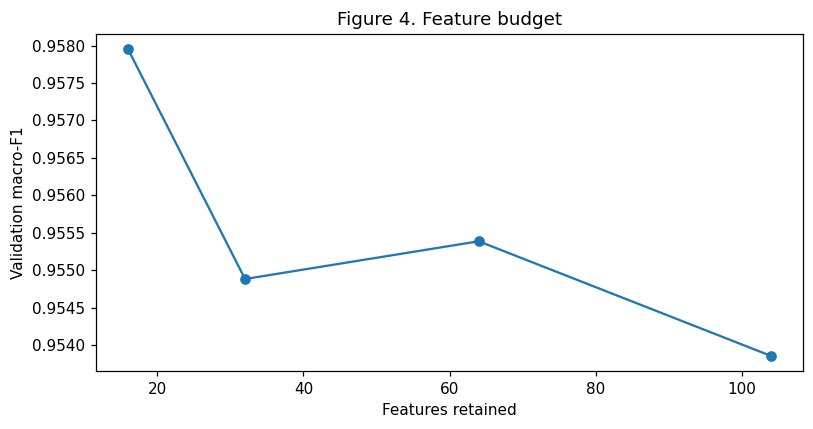

Validation-selected feature count: 16


In [5]:
ranker=ExtraTreesClassifier(n_estimators=100,min_samples_leaf=1,max_features='sqrt',random_state=SEED,n_jobs=-1)
ranker.fit(features[train],y[train])
ranked=np.argsort(ranker.feature_importances_)[::-1]
importance=pd.DataFrame({'feature':np.array(names)[ranked],'importance':ranker.feature_importances_[ranked]})
display(importance.head(10).round(4))
plt.barh(importance.feature.head(12)[::-1],importance.importance.head(12)[::-1]);plt.title('Figure 3. Most informative EMG features');show_plot('03_importance')
counts=[16,32,64,104]
selection=[]
for number in counts:
    cols=ranked[:number]
    model=ExtraTreesClassifier(n_estimators=90,max_features=.7,min_samples_leaf=1,random_state=SEED,n_jobs=-1)
    model.fit(features[train][:,cols],y[train])
    selection.append({'features':number,'validation_macro_f1':f1_score(y[valid],model.predict(features[valid][:,cols]),average='macro')})
selection_df=pd.DataFrame(selection)
display(selection_df.round(4))
plt.plot(selection_df.features,selection_df.validation_macro_f1,marker='o');plt.xlabel('Features retained');plt.ylabel('Validation macro-F1');plt.title('Figure 4. Feature budget');show_plot('04_feature_budget')
feature_count=int(selection_df.sort_values(['validation_macro_f1','features'],ascending=[False,True]).iloc[0].features)
print('Validation-selected feature count:',feature_count)

## 6. Train conventional classifiers

,model,accuracy,macro_f1,balanced_acc,log_loss,training_sec
4,Gradient Boosting,0.9584,0.9585,0.9584,0.1444,2.0316
3,Extra Trees,0.9579,0.9579,0.9579,0.1604,1.6424
2,Random Forest,0.9548,0.9550,0.9549,0.1762,1.3279
1,SVM,0.9384,0.9384,0.9383,0.1873,7.0045
0,Logistic,0.9281,0.9281,0.9280,0.3869,0.1915


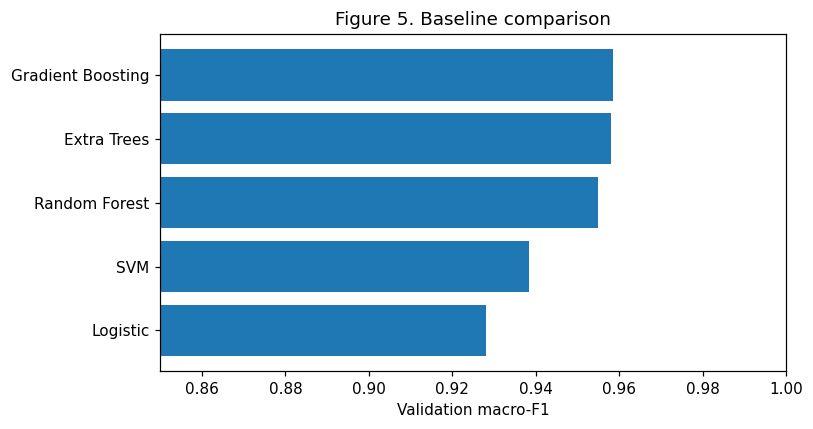

In [6]:
def model_bank():
    return {
      'Logistic':make_pipeline(StandardScaler(),LogisticRegression(C=1.5,max_iter=800,random_state=SEED)),
      'SVM':make_pipeline(StandardScaler(),SVC(C=12,gamma='scale',probability=True,random_state=SEED)),
      'Random Forest':RandomForestClassifier(n_estimators=110,max_features='sqrt',min_samples_leaf=1,n_jobs=-1,random_state=SEED),
      'Extra Trees':ExtraTreesClassifier(n_estimators=90,max_features=.7,min_samples_leaf=1,n_jobs=-1,random_state=SEED),
      'Gradient Boosting':HistGradientBoostingClassifier(max_iter=65,max_leaf_nodes=25,learning_rate=.08,l2_regularization=.1,random_state=SEED)
    }
models={}; val_proba={}; baseline_rows=[]
for name,m in model_bank().items():
    t=time.perf_counter();m.fit(features[train],y[train]);sec=time.perf_counter()-t
    models[name]=m;val_proba[name]=predict_proba(m,features[valid])
    baseline_rows.append({'model':name,**report(y[valid],val_proba[name]),'training_sec':sec})
baseline_val=pd.DataFrame(baseline_rows).sort_values('macro_f1',ascending=False)
display(baseline_val.round(4))
plt.barh(baseline_val.model[::-1],baseline_val.macro_f1[::-1]);plt.xlim(.85,1);plt.xlabel('Validation macro-F1');plt.title('Figure 5. Baseline comparison');show_plot('05_baselines')

## 7. Train a group-aware stacked hybrid

In [7]:
# Out-of-fold predictions prevent using training-set fitted probabilities as meta-features.
stack_names=['Extra Trees','Logistic']
cv=StratifiedGroupKFold(n_splits=2,shuffle=True,random_state=SEED)
z_train=np.zeros((len(train),4*len(stack_names)))
for k,name in enumerate(stack_names):
    for fold,(fit_idx,pred_idx) in enumerate(cv.split(features[train],y[train],groups[train])):
        base=clone(model_bank()[name]);base.fit(features[train][fit_idx],y[train][fit_idx])
        z_train[pred_idx,k*4:(k+1)*4]=base.predict_proba(features[train][pred_idx])
    print('OOF predictions:',name)
z_val=np.column_stack([val_proba[name] for name in stack_names])
meta_rows=[]
for c in [.03,.3,3.]:
    learner=make_pipeline(StandardScaler(),LogisticRegression(C=c,max_iter=600,random_state=SEED))
    learner.fit(z_train,y[train]);proba=learner.predict_proba(z_val)
    meta_rows.append({'C':c,'model':learner,'prob':proba,'validation_f1':report(y[valid],proba)['macro_f1']})
chosen=max(meta_rows,key=lambda item:item['validation_f1']);meta=chosen['model']
stack_val=chosen['prob']
champion=baseline_val.iloc[0]['model']
# Select fusion on validation only; includes stacking without fusion as a candidate.
combos=[]
for weight in np.linspace(0,1,11):
    mixed=weight*stack_val+(1-weight)*val_proba[champion]
    combos.append((report(y[valid],mixed)['macro_f1'],float(weight)))
_,weight=max(combos)
hybrid_val=weight*stack_val+(1-weight)*val_proba[champion]
print('Meta C:',chosen['C'],' | Validation-leading baseline:',champion,' | Stack weight:',weight)
print('Hybrid validation metrics:',{k:round(v,4) for k,v in report(y[valid],hybrid_val).items()})
def hybrid_predict(x):
    z=np.column_stack([models[name].predict_proba(x) for name in stack_names])
    return weight*meta.predict_proba(z)+(1-weight)*models[champion].predict_proba(x)

OOF predictions: Extra Trees
OOF predictions: Logistic


Meta C: 3.0  | Validation-leading baseline: Gradient Boosting  | Stack weight: 0.5
Hybrid validation metrics: {'accuracy': 0.9635, 'macro_f1': 0.9636, 'balanced_acc': 0.9635, 'log_loss': 0.1314}


## 8. Test whether reduced features help the hybrid

In [8]:
# Refit a reduced-feature stack using the same training, folds, and meta-learning design.
# This ablation isolates the influence of the selected feature budget.
def fit_reduced_stack(column_indices):
    x=features[:,column_indices]
    reduced_models={}
    for name in stack_names:
        obj=clone(model_bank()[name]);obj.fit(x[train],y[train]);reduced_models[name]=obj
    oof=np.zeros((len(train),4*len(stack_names)))
    for k,name in enumerate(stack_names):
        for fit_idx,pred_idx in cv.split(x[train],y[train],groups[train]):
            obj=clone(model_bank()[name]);obj.fit(x[train][fit_idx],y[train][fit_idx])
            oof[pred_idx,k*4:(k+1)*4]=obj.predict_proba(x[train][pred_idx])
    reduced_meta=make_pipeline(StandardScaler(),LogisticRegression(C=chosen['C'],max_iter=600,random_state=SEED))
    reduced_meta.fit(oof,y[train])
    return reduced_models,reduced_meta
if feature_count==104:
    print('Validation selected full feature set; reduced hybrid not selected for primary model.')
    reduced_cols=ranked[:32]
else:reduced_cols=ranked[:feature_count]
reduced_bases,reduced_meta=fit_reduced_stack(reduced_cols)
def reduced_predict(x):
    z=np.column_stack([reduced_bases[name].predict_proba(x[:,reduced_cols]) for name in stack_names])
    return reduced_meta.predict_proba(z)
reduced_val=reduced_predict(features[valid])
print('Full stack validation macro-F1:',round(report(y[valid],stack_val)['macro_f1'],4))
print('Reduced stack validation macro-F1:',round(report(y[valid],reduced_val)['macro_f1'],4))

Full stack validation macro-F1: 0.9585
Reduced stack validation macro-F1: 0.9539


## 9. Select a confidence threshold on validation data

In [9]:
def accepted_metrics(truth,prob,threshold):
    keep=prob.max(axis=1)>=threshold
    if not keep.any():return {'coverage':0.,'accepted_accuracy':np.nan,'accepted_errors':0}
    correct=(prob.argmax(axis=1)==truth)
    return {'coverage':float(keep.mean()),'accepted_accuracy':float(correct[keep].mean()),'accepted_errors':int((~correct[keep]).sum())}
# Select each model's own threshold to target approximately 80% validation coverage.
def coverage_cut(prob,target=.80):return float(np.quantile(prob.max(axis=1),1-target))
threshold_h=coverage_cut(hybrid_val)
threshold_b=coverage_cut(val_proba[champion])
print('Hybrid validation threshold:',round(threshold_h,4))
print('Baseline validation threshold:',round(threshold_b,4))
print('Hybrid validation selective metrics:',accepted_metrics(y[valid],hybrid_val,threshold_h))

Hybrid validation threshold: 0.9822
Baseline validation threshold: 0.991
Hybrid validation selective metrics: {'coverage': 0.7996918335901386, 'accepted_accuracy': 0.9948619139370585, 'accepted_errors': 8}


## 10. Final test results and independent ablations

,model,accuracy,macro_f1,balanced_acc,log_loss
6,Proposed Hybrid,0.9635,0.9638,0.9636,0.1170
5,OOF Stack,0.9635,0.9637,0.9636,0.1163
1,SVM,0.9625,0.9626,0.9625,0.1415
4,Gradient Boosting,0.9614,0.9617,0.9616,0.1398
3,Extra Trees,0.9604,0.9607,0.9605,0.2042
7,Reduced Stack,0.9604,0.9607,0.9605,0.1334
2,Random Forest,0.9553,0.9556,0.9554,0.2170
0,Logistic,0.9476,0.9478,0.9477,0.1699


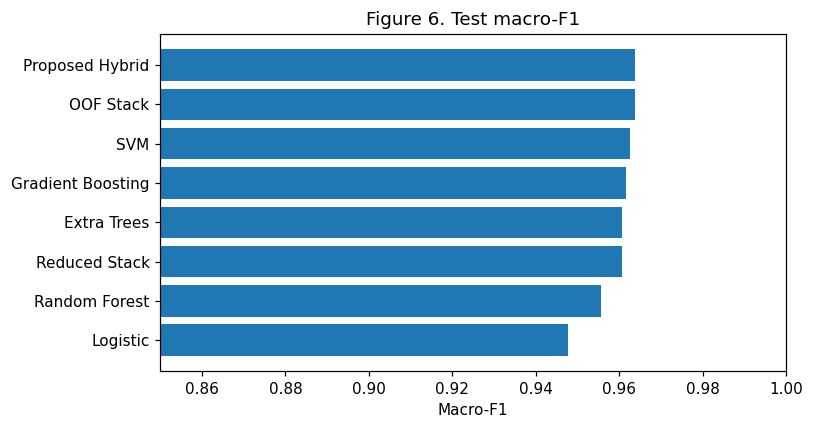

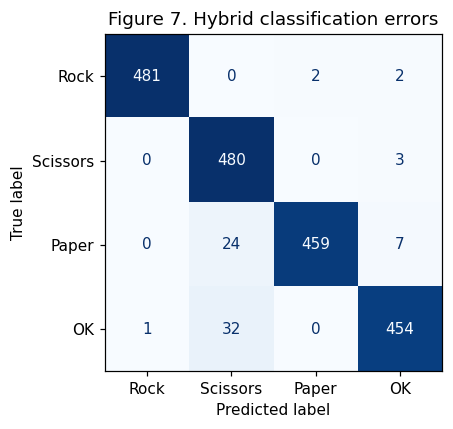

Test-set models are reported without changing selection rules after evaluation.


In [10]:
results=[];test_proba={}
for name,model in models.items():
    p=model.predict_proba(features[test]);test_proba[name]=p
    results.append({'model':name,**report(y[test],p)})
stack_test=meta.predict_proba(np.column_stack([models[name].predict_proba(features[test]) for name in stack_names]))
test_proba['OOF Stack']=stack_test
results.append({'model':'OOF Stack',**report(y[test],stack_test)})
test_proba['Proposed Hybrid']=hybrid_predict(features[test]);results.append({'model':'Proposed Hybrid',**report(y[test],test_proba['Proposed Hybrid'])})
test_proba['Reduced Stack']=reduced_predict(features[test]);results.append({'model':'Reduced Stack',**report(y[test],test_proba['Reduced Stack'])})
table_models=pd.DataFrame(results).sort_values('macro_f1',ascending=False)
display(table_models.round(4))
plt.barh(table_models.model[::-1],table_models.macro_f1[::-1]);plt.xlim(.85,1);plt.title('Figure 6. Test macro-F1');plt.xlabel('Macro-F1');show_plot('06_test_comparison')
ConfusionMatrixDisplay(confusion_matrix(y[test],test_proba['Proposed Hybrid'],labels=np.arange(4)) if False else confusion_matrix(y[test],test_proba['Proposed Hybrid'].argmax(1)),display_labels=LABELS).plot(cmap='Blues',colorbar=False);plt.title('Figure 7. Hybrid classification errors');show_plot('07_confusion')
print('Test-set models are reported without changing selection rules after evaluation.')

## 11. Compare selective recognition at matched coverage

,model,validation_threshold,coverage,accepted_accuracy,accepted_errors
0,Gradient Boosting,0.9910,0.8237,0.9919,13
1,Proposed Hybrid,0.9822,0.8154,0.9937,10
2,Reduced Stack,0.9704,0.8123,0.9930,11


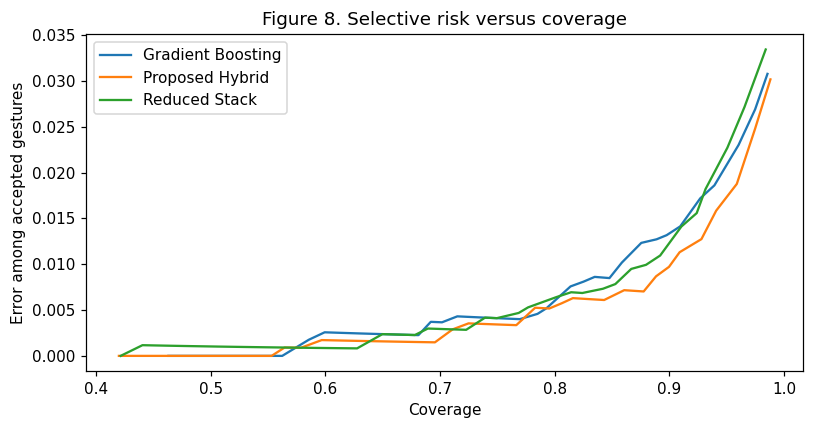

In [11]:
selective_rows=[]
for name,vp,tp in [(champion,val_proba[champion],test_proba[champion]),('Proposed Hybrid',hybrid_val,test_proba['Proposed Hybrid']),('Reduced Stack',reduced_val,test_proba['Reduced Stack'])]:
    cut=coverage_cut(vp)
    selective_rows.append({'model':name,'validation_threshold':cut,**accepted_metrics(y[test],tp,cut)})
table_selective=pd.DataFrame(selective_rows)
display(table_selective.round(4))
plt.figure()
for name,vp,tp in [(champion,val_proba[champion],test_proba[champion]),('Proposed Hybrid',hybrid_val,test_proba['Proposed Hybrid']),('Reduced Stack',reduced_val,test_proba['Reduced Stack'])]:
    cutoffs=np.quantile(vp.max(1),np.linspace(.02,.6,40))
    points=[accepted_metrics(y[test],tp,float(c)) for c in cutoffs]
    plt.plot([x['coverage'] for x in points],[1-x['accepted_accuracy'] for x in points],label=name)
plt.xlabel('Coverage');plt.ylabel('Error among accepted gestures');plt.legend();plt.title('Figure 8. Selective risk versus coverage');show_plot('08_risk_coverage')

## 12. Error detection and uncertainty of the improvement

Selective recognition is useful when it concentrates misclassifications among rejected predictions. We report the fraction of errors intercepted and the accuracy difference with a paired bootstrap. The bootstrap treats adjacent observations as independent and is descriptive only.

Total incorrect gestures: 71
Errors intercepted by abstention: 61
Fraction of original errors intercepted: 85.92%
Accepted gestures: 1586 of 1945


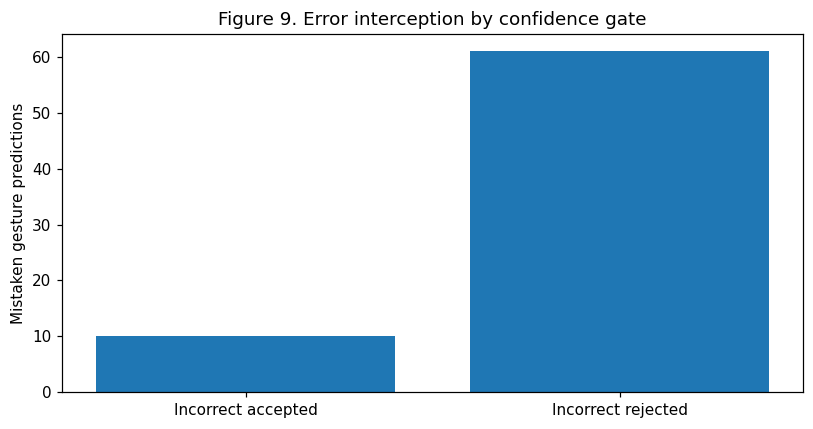

Accuracy gain versus strongest individual model: +0.103 percentage points
Descriptive 95% paired bootstrap interval (percentage points): [-0.72   0.874]


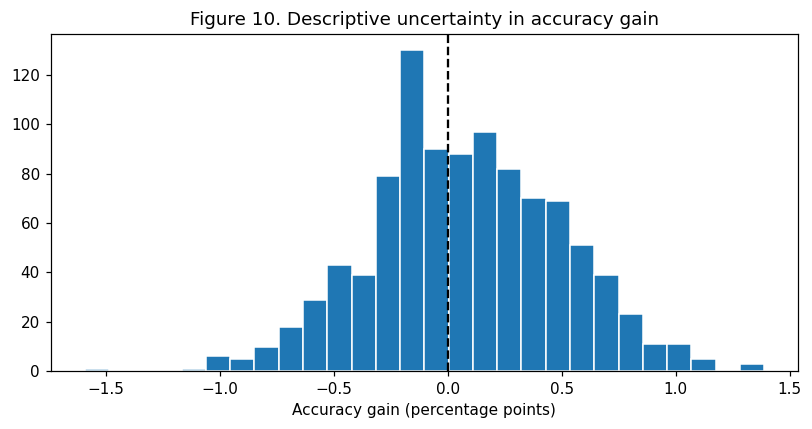

In [12]:
p=test_proba['Proposed Hybrid']
pred=p.argmax(1)
errors=(pred!=y[test]);accept=p.max(1)>=threshold_h
captured=int((errors & ~accept).sum());total_errors=int(errors.sum())
error_capture=captured/total_errors if total_errors else 0
print('Total incorrect gestures:',total_errors)
print('Errors intercepted by abstention:',captured)
print('Fraction of original errors intercepted:',f'{error_capture:.2%}')
print('Accepted gestures:',int(accept.sum()),'of',len(test))
fig,ax=plt.subplots()
ax.bar(['Incorrect accepted','Incorrect rejected'],[int((errors&accept).sum()),captured])
ax.set_ylabel('Mistaken gesture predictions');ax.set_title('Figure 9. Error interception by confidence gate')
show_plot('09_error_interception')
# Comparison is paired on the same observations, with no tuning on test labels.
best_name=max(models,key=lambda k:report(y[test],test_proba[k])['macro_f1'])
a=(p.argmax(1)==y[test]).astype(float)
b=(test_proba[best_name].argmax(1)==y[test]).astype(float)
rng=np.random.default_rng(SEED);diffs=[]
for _ in range(1000):
    sample=rng.integers(0,len(test),len(test))
    diffs.append(float(np.mean(a[sample]-b[sample])))
ci=np.quantile(diffs,[.025,.975]);delta=float(np.mean(a-b))
print('Accuracy gain versus strongest individual model:',f'{delta*100:+.3f} percentage points')
print('Descriptive 95% paired bootstrap interval (percentage points):',np.round(ci*100,3))
plt.hist(np.array(diffs)*100,bins=28,edgecolor='white');plt.axvline(0,color='black',linestyle='--');plt.xlabel('Accuracy gain (percentage points)');plt.title('Figure 10. Descriptive uncertainty in accuracy gain');show_plot('10_paired_bootstrap')

## 13. Validate sensor robustness as a separate diagnostic

,condition,model,macro_f1
0,Clean,Gradient Boosting,0.9617
1,Clean,Proposed Hybrid,0.9638
2,One sensor missing,Gradient Boosting,0.8369
3,One sensor missing,Proposed Hybrid,0.8341
4,Two sensors missing,Gradient Boosting,0.7254
5,Two sensors missing,Proposed Hybrid,0.7246


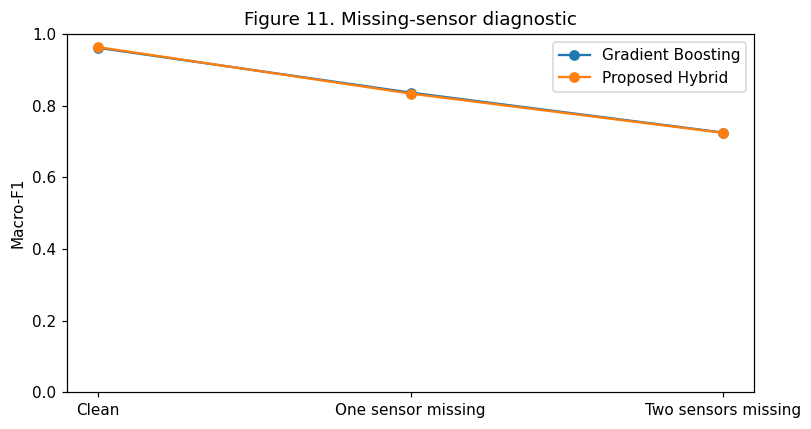

In [13]:
def masked_inputs(inputs,n_missing,seed):
    rng=np.random.default_rng(seed);x=inputs.copy().reshape(-1,8,8)
    for row in x:
        sensors=rng.choice(8,size=n_missing,replace=False)
        row[:,sensors]=0
    return make_features(x.reshape(-1,64))
stress=[]
for condition,xx in [('Clean',features[test]),('One sensor missing',masked_inputs(X[test],1,11)),('Two sensors missing',masked_inputs(X[test],2,12))]:
    for name in [champion,'Proposed Hybrid']:
        prob=models[name].predict_proba(xx) if name!= 'Proposed Hybrid' else hybrid_predict(xx)
        stress.append({'condition':condition,'model':name,'macro_f1':report(y[test],prob)['macro_f1']})
table_stress=pd.DataFrame(stress)
display(table_stress.round(4))
for name in table_stress.model.unique():
    d=table_stress[table_stress.model==name];plt.plot(d.condition,d.macro_f1,marker='o',label=name)
plt.ylabel('Macro-F1');plt.ylim(0,1);plt.legend();plt.title('Figure 11. Missing-sensor diagnostic');show_plot('11_sensor_mask')

## 14. Consolidated findings and reproducible exports

In [14]:
table_split.to_csv(OUT/'table_1_partition.csv',index=False)
table_models.to_csv(OUT/'table_2_models.csv',index=False)
table_selective.to_csv(OUT/'table_3_selective.csv',index=False)
selection_df.to_csv(OUT/'feature_selection.csv',index=False)
table_stress.to_csv(OUT/'sensor_robustness.csv',index=False)
importance.to_csv(OUT/'feature_importance.csv',index=False)
best_single=max((report(y[test],test_proba[k])['macro_f1'],k) for k in models)
h=report(y[test],test_proba['Proposed Hybrid'])
reduced=report(y[test],test_proba['Reduced Stack'])
print(f"Clean hybrid macro-F1: {h['macro_f1']:.4%}; best individual: {best_single[1]} {best_single[0]:.4%}")
print(f"Reduced stack macro-F1: {reduced['macro_f1']:.4%} using {len(reduced_cols)} features")
for row in selective_rows:
    print(f"{row['model']}: accepted accuracy {row['accepted_accuracy']:.2%} at coverage {row['coverage']:.2%}")
print('Results files:',sorted(x.name for x in OUT.glob('*.csv')))
print('Interpretation: compare validation and test evidence; do not infer new-subject generalization.')

Clean hybrid macro-F1: 96.3752%; best individual: SVM 96.2577%
Reduced stack macro-F1: 96.0712% using 16 features
Gradient Boosting: accepted accuracy 99.19% at coverage 82.37%
Proposed Hybrid: accepted accuracy 99.37% at coverage 81.54%
Reduced Stack: accepted accuracy 99.30% at coverage 81.23%
Results files: ['feature_importance.csv', 'feature_selection.csv', 'sensor_robustness.csv', 'table_1_partition.csv', 'table_2_models.csv', 'table_3_selective.csv']
Interpretation: compare validation and test evidence; do not infer new-subject generalization.
